# 08 · Ultimate Williams–Otto neural-surrogate comparison

This notebook compares four end-to-end neural-surrogate pipelines on one fixed
Williams–Otto train/validation/test split:

1. **Smooth tanh** — data-only Keras training and smooth tanh inference.
2. **PWL tanh** — the same data-trained weights evaluated and embedded with the
   shared piecewise-linear tanh approximation.
3. **PWL tanh + PI** — physics-informed training followed by the same PWL
   approximation.
4. **SOSX training** — direct bounded optimization of a one-hidden-layer
   PWL-tanh network under MAE, with a fixed readout and SOSX branching.

The first two rows intentionally share trained weights. There is currently no
separate gradient-based PWL activation trainer in PWLNet; post-training PWL
conversion isolates the approximation cost from training variability.

The notebook reports:

- train/validation/test regression metrics;
- four parity plots;
- validation-loss histories and final validation MAE;
- wall-clock CPU time for training;
- wall-clock time and process-level quality for constrained Williams–Otto
  optimization.

The solve benchmark uses each pipeline's native deployment path. Consequently,
the smooth model is an NLP, the two converted PWL models are big-M MILPs, and the
SOSX-trained model is solved by branch-and-LP. Solver times are therefore an
end-to-end pipeline comparison, not a controlled formulation microbenchmark.

In [1]:
from __future__ import annotations

import os
import sys
import time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
os.environ.setdefault("MPLCONFIGDIR", "/tmp/pwlnet-matplotlib")


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "src" / "pwlnet").exists() and (candidate / "pyproject.toml").exists():
            return candidate
    raise RuntimeError("Could not find the PWLNet project root.")


ROOT = find_project_root(Path.cwd().resolve())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pwlnet import PWLNet, regression_metrics, solve_sosx, train_val_test_split
from pwlnet.core.network import NetworkDefinition
from pwlnet.formulations.pyomo_pwl import evaluate_tanh_pwl_network
from pwlnet.processes.williams_otto import (
    EXACT_OPTIMUM,
    INPUT_NAMES,
    OUTPUT_NAMES,
    WilliamsOttoParameters,
    generate_dataset,
    solve_surrogate_optimization_model,
)
from pwlnet.solvers import find_ipopt

plt.style.use("seaborn-v0_8-whitegrid")
params = WilliamsOttoParameters()

## 1 · Shared benchmark configuration

`FAST_MODE=True` keeps SOSX training practical on a laptop. Set it to `False`
for the larger data set and wider network. The same split, architecture, random
seed, scaling, and PWL breakpoints are used by every pipeline.

SOSX currently supports a single hidden layer and fixed output weights. It is
warm-started from the data-trained tanh model, making its comparison meaningful:
SOSX globally re-optimizes the input layer and biases for the PWL-MAE problem
while retaining the same readout.

In [2]:
FAST_MODE = False
RANDOM_SEED = 7
N_SAMPLES = 40 if FAST_MODE else 120
HIDDEN = 3 if FAST_MODE else 6
EPOCHS = 300 if FAST_MODE else 800
BATCH_SIZE = 16
PWL_BREAKPOINTS = 5
PWL_FB_SEGMENTS = 10
DIAGNOSTIC_GRID_AXIS = 45 if FAST_MODE else 60
BREAKPOINT_SWEEP = [3, 5, 7]
NOISE_STRESS_FRACTIONS = [0.005, 0.01, 0.02]
REPEATED_SEED_COUNT = 3
RUN_EXTENDED_SOSX_DIAGNOSTICS = False
SOLVER = "appsi_gurobi"

SOSX_PARALLEL = False       # Set True when Ray is installed.
SOSX_WORKERS = None         # None -> cpu_count - 1 in parallel mode.
SOSX_MAX_NODES = 1500 if FAST_MODE else 15000
SOSX_TIME_LIMIT = 120.0 if FAST_MODE else 1500.0
SOSX_RELATIVE_GAP = 1e-3

print(
    f"samples={N_SAMPLES}, hidden={HIDDEN}, breakpoints={PWL_BREAKPOINTS}, "
    f"solver={SOLVER}, sosx_parallel={SOSX_PARALLEL}"
)

samples=120, hidden=6, breakpoints=5, solver=appsi_gurobi, sosx_parallel=False


In [3]:
data = generate_dataset(
    n_samples=N_SAMPLES,
    method="lhs",
    random_state=RANDOM_SEED,
    as_frame=True,
)
split = train_val_test_split(
    data,
    val_size=0.2,
    test_size=0.2,
    random_state=RANDOM_SEED,
)
train_df, val_df, test_df = split.train, split.validation, split.test


def split_xy(frame):
    return (
        frame[INPUT_NAMES].to_numpy(dtype=float),
        frame[OUTPUT_NAMES].to_numpy(dtype=float),
    )


X_train, y_train = split_xy(train_df)
X_val, y_val = split_xy(val_df)
X_test, y_test = split_xy(test_df)

print(
    f"data: {len(data)} -> train {len(train_df)} / "
    f"validation {len(val_df)} / test {len(test_df)}"
)

data: 120 -> train 72 / validation 24 / test 24


## 2 · Train the three native models

Training time is measured around the complete public API call. The PWL data-only
pipeline reuses the smooth model, so its incremental conversion cost is zero and
its end-to-end fit cost equals the smooth fit cost.

In [4]:
common_keras = dict(
    hidden_layers=[HIDDEN],
    activation="tanh",
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    early_stopping_patience=40,
    random_seed=RANDOM_SEED,
    verbose=0,
)

t0 = time.perf_counter()
smooth = PWLNet.train(X_train, y_train, loss="mse", **common_keras)
smooth_fit_seconds = time.perf_counter() - t0

print(smooth.summary())
print(f"smooth fit: {smooth_fit_seconds:.3f} s")

NetworkDefinition: 2 inputs -> 6 outputs, 2 layers, 6 hidden neurons, 60 parameters
layer   n_in  n_out activation   params
    0      2      6       tanh       18
    1      6      6     linear       42
smooth fit: 74.766 s


In [5]:
PI_WEIGHTS = {"closure": 1.0, "bounds": 1.0}

t0 = time.perf_counter()
pi = PWLNet.train_physics_informed(
    X_train,
    y_train,
    hidden_layers=[HIDDEN],
    activation="tanh",
    physics="williams_otto",
    physics_weights=PI_WEIGHTS,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    early_stopping_patience=40,
    random_seed=RANDOM_SEED,
    verbose=0,
)
pi_fit_seconds = time.perf_counter() - t0

print(pi.summary())
print(f"PI fit: {pi_fit_seconds:.3f} s")

NetworkDefinition: 2 inputs -> 6 outputs, 2 layers, 6 hidden neurons, 60 parameters
layer   n_in  n_out activation   params
    0      2      6       tanh       18
    1      6      6     linear       42
PI fit: 14.309 s


In [6]:
t0 = time.perf_counter()
sosx = PWLNet.train_sosx(
    X_train,
    y_train,
    hidden_neurons=HIDDEN,
    validation_data=(X_val, y_val),
    initial_network=smooth.network,
    breakpoints=PWL_BREAKPOINTS,
    solver=SOLVER,
    solver_options={"persistent": True},
    max_nodes=SOSX_MAX_NODES,
    time_limit=SOSX_TIME_LIMIT,
    relative_gap=SOSX_RELATIVE_GAP,
    random_seed=RANDOM_SEED,
    parallel=SOSX_PARALLEL,
    n_workers=SOSX_WORKERS,
    verbose=False,
)
sosx_incremental_seconds = time.perf_counter() - t0
sosx_total_seconds = smooth_fit_seconds + sosx_incremental_seconds

print(sosx.summary())
print(
    f"SOSX refinement: {sosx_incremental_seconds:.3f} s; "
    f"end-to-end including warm-start fit: {sosx_total_seconds:.3f} s"
)
print(
    f"status={sosx.trainer.result_.status}, nodes={sosx.trainer.n_nodes_}, "
    f"gap={sosx.trainer.optimality_gap_}, workers={sosx.trainer.n_workers_}"
)


def pin_operating_bounds(model: PWLNet) -> None:
    network = model.network
    model.network = NetworkDefinition(
        layers=network.layers,
        input_scaler=network.input_scaler,
        output_scaler=network.output_scaler,
        input_bounds=[
            tuple(map(float, params.fb_bounds)),
            tuple(map(float, params.tr_bounds)),
        ],
    )


for fitted_model in (smooth, pi, sosx):
    pin_operating_bounds(fitted_model)

NetworkDefinition: 2 inputs -> 6 outputs, 2 layers, 6 hidden neurons, 60 parameters
layer   n_in  n_out activation   params
    0      2      6       tanh       18
    1      6      6     linear       42
SOSX refinement: 1.526 s; end-to-end including warm-start fit: 76.292 s
status=optimal, nodes=2, gap=0.0, workers=None


## 3 · Four prediction pipelines

All PWL predictions use `evaluate_tanh_pwl_network`, the same approximation used
by the Pyomo embeddings. This is important: `NetworkDefinition.predict` always
evaluates the stored smooth tanh activation, including for a network whose
weights were found by SOSX training.

In [7]:
predictors = {
    "Smooth tanh": lambda X: smooth.predict(X),
    "PWL tanh": lambda X: evaluate_tanh_pwl_network(
        smooth.network, X, breakpoints=PWL_BREAKPOINTS
    ),
    "PWL tanh + PI": lambda X: evaluate_tanh_pwl_network(
        pi.network, X, breakpoints=PWL_BREAKPOINTS
    ),
    "SOSX trained": lambda X: evaluate_tanh_pwl_network(
        sosx.network, X, breakpoints=PWL_BREAKPOINTS
    ),
}

predictions = {
    method: {
        "train": predict(X_train),
        "validation": predict(X_val),
        "test": predict(X_test),
    }
    for method, predict in predictors.items()
}

## 4 · Train/validation/test metrics

In [8]:
metric_rows = []
truth = {"train": y_train, "validation": y_val, "test": y_test}

for method, split_predictions in predictions.items():
    for split_name, y_pred in split_predictions.items():
        metric_rows.append(
            {
                "method": method,
                "split": split_name,
                **regression_metrics(truth[split_name], y_pred),
            }
        )

metrics = pd.DataFrame(metric_rows)
display(metrics)
display(
    metrics[metrics["split"] == "test"]
    .set_index("method")[["MAE", "RMSE", "R2"]]
    .sort_values("MAE")
)

,method,split,MAE,MSE,RMSE,R2,n_samples
0,Smooth tanh,train,0.002566,0.000014,0.003752,0.989734,72
1,Smooth tanh,validation,0.002586,0.000013,0.003553,0.989362,24
2,Smooth tanh,test,0.002721,0.000017,0.004096,0.988941,24
3,PWL tanh,train,0.002884,0.000021,0.004551,0.984897,72
4,PWL tanh,validation,0.002440,0.000013,0.003658,0.988724,24
5,PWL tanh,test,0.003336,0.000026,0.005087,0.982947,24
6,PWL tanh + PI,train,0.002491,0.000015,0.003836,0.989269,72
7,PWL tanh + PI,validation,0.002353,0.000014,0.003708,0.988411,24
8,PWL tanh + PI,test,0.002859,0.000019,0.004348,0.987540,24
9,SOSX trained,train,0.002465,0.000016,0.003951,0.988616,72


,MAE,RMSE,R2
method,,,
Smooth tanh,0.002721,0.004096,0.988941
PWL tanh + PI,0.002859,0.004348,0.987540
SOSX trained,0.003110,0.004695,0.985471
PWL tanh,0.003336,0.005087,0.982947


## 5 · Test-set parity plots

Each training pipeline now gets its own figure, with one panel per mass-fraction
output. Matching axis limits are used for a given output across all four figures,
so changes in scatter around the diagonal can be compared directly.

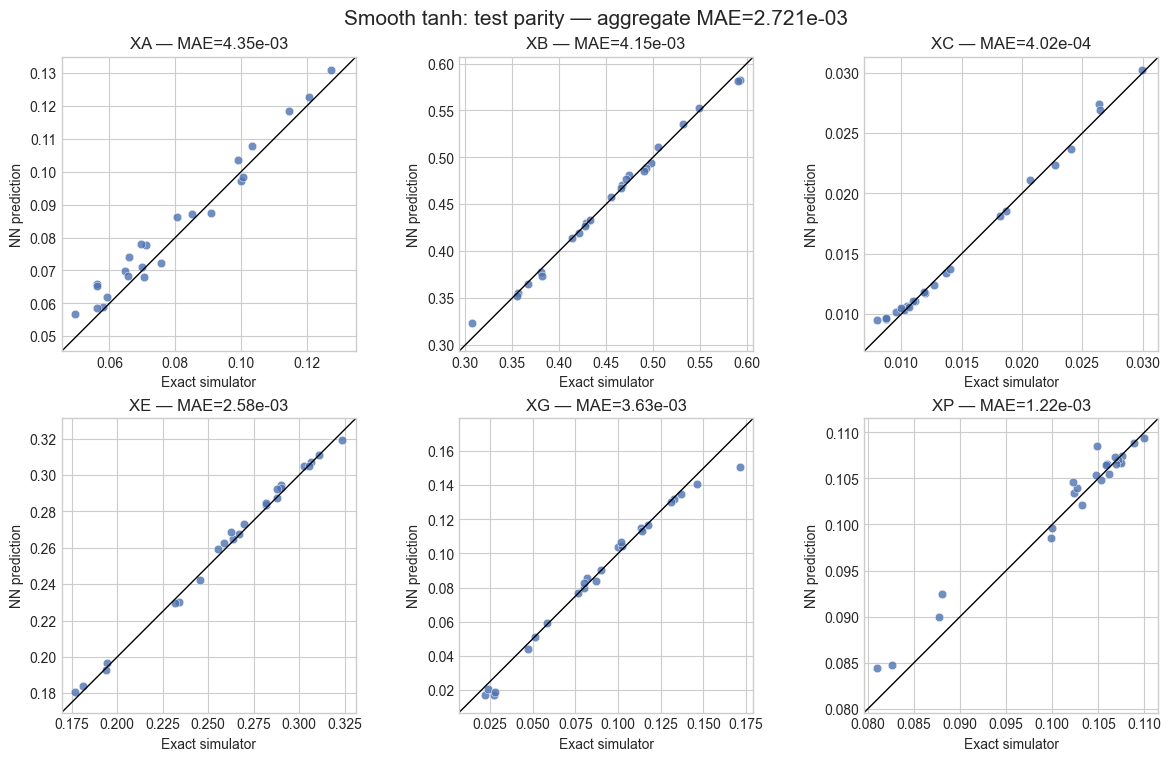

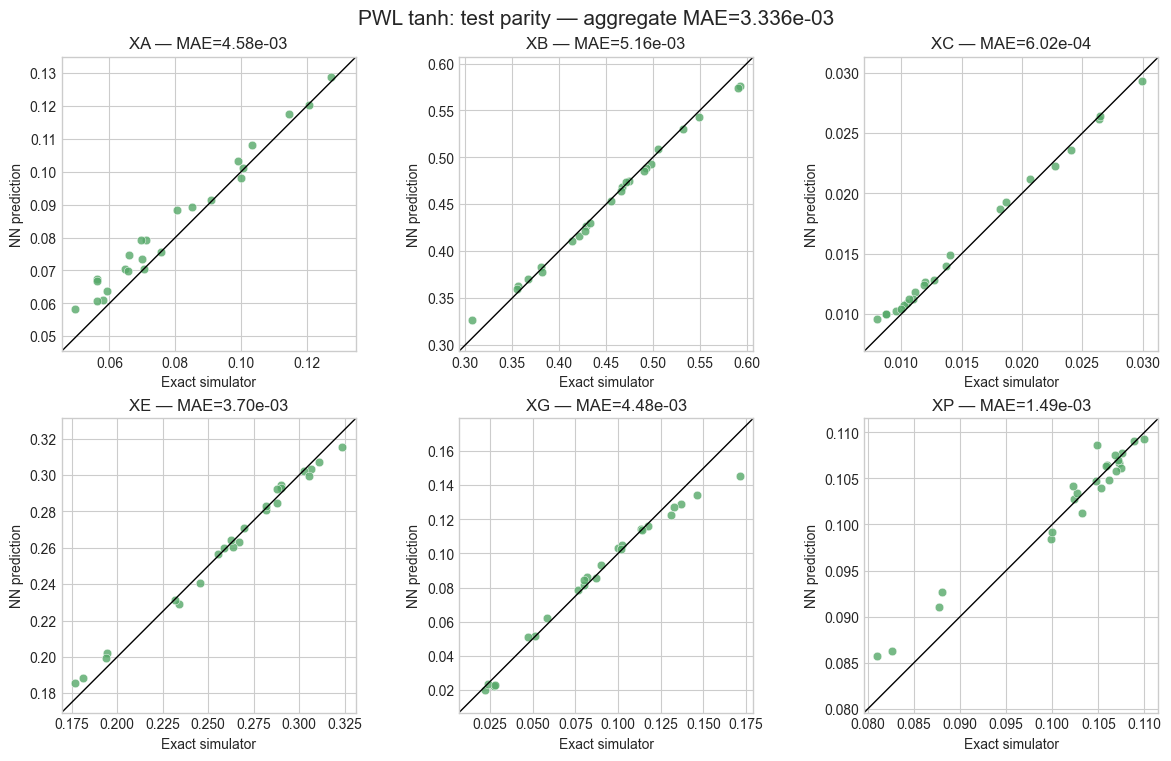

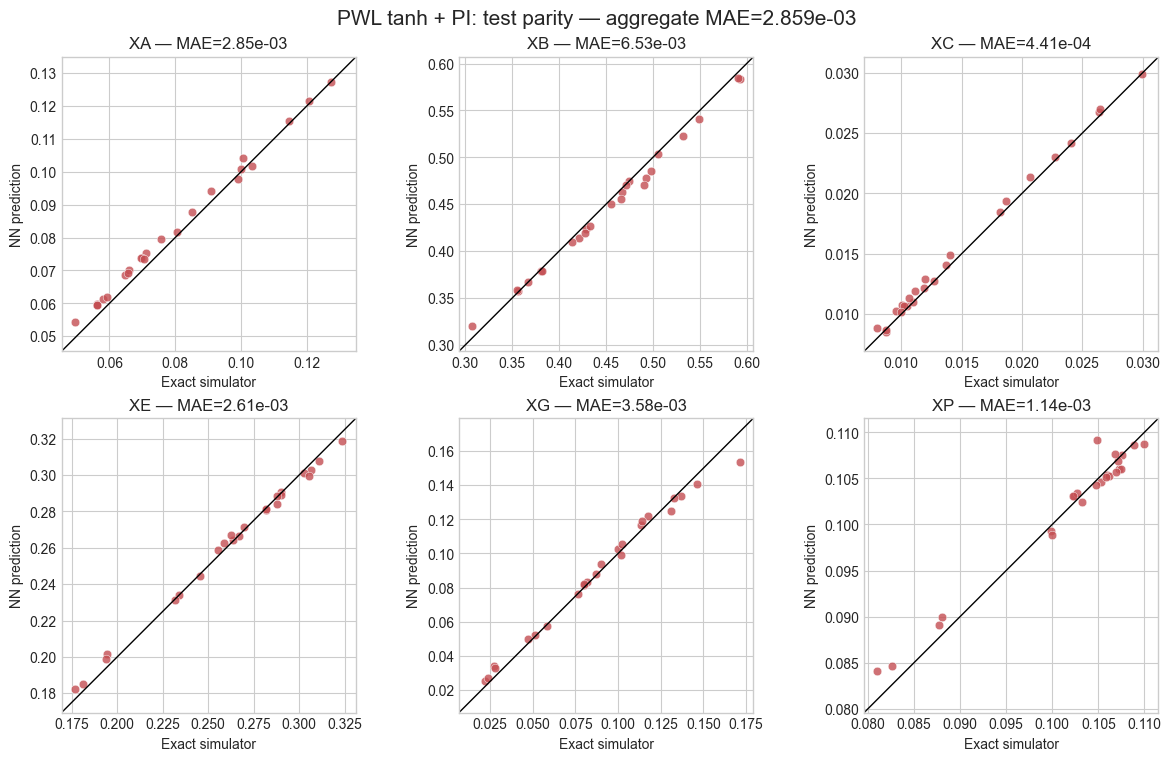

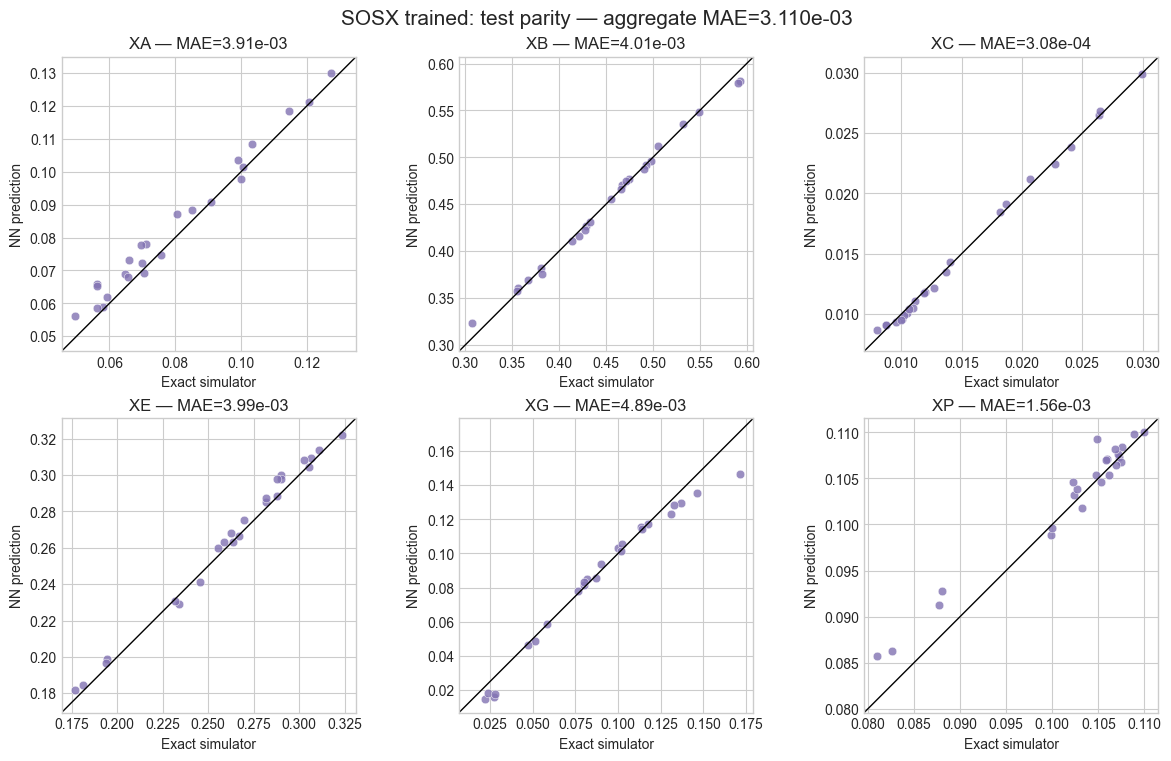

In [9]:
method_colors = {
    "Smooth tanh": "#4C72B0",
    "PWL tanh": "#55A868",
    "PWL tanh + PI": "#C44E52",
    "SOSX trained": "#8172B2",
}

# Fix one plotting range per output and reuse it for every method.
output_limits = []
for j in range(len(OUTPUT_NAMES)):
    values = [y_test[:, j]] + [
        split_predictions["test"][:, j]
        for split_predictions in predictions.values()
    ]
    lo = float(min(value.min() for value in values))
    hi = float(max(value.max() for value in values))
    pad = 0.05 * max(hi - lo, 1e-8)
    output_limits.append((lo - pad, hi + pad))

for method, split_predictions in predictions.items():
    y_pred = split_predictions["test"]
    fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), constrained_layout=True)

    for j, (ax, output) in enumerate(zip(axes.ravel(), OUTPUT_NAMES)):
        lo, hi = output_limits[j]
        output_mae = float(np.mean(np.abs(y_pred[:, j] - y_test[:, j])))
        ax.scatter(
            y_test[:, j],
            y_pred[:, j],
            s=38,
            alpha=0.8,
            color=method_colors[method],
            edgecolor="white",
            linewidth=0.4,
        )
        ax.plot([lo, hi], [lo, hi], color="black", lw=1)
        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)
        ax.set_aspect("equal", adjustable="box")
        ax.set_title(f"{output} — MAE={output_mae:.2e}")
        ax.set_xlabel("Exact simulator")
        ax.set_ylabel("NN prediction")

    aggregate_mae = metrics.query(
        "method == @method and split == 'test'"
    )["MAE"].iloc[0]
    fig.suptitle(f"{method}: test parity — aggregate MAE={aggregate_mae:.3e}", fontsize=15)
    plt.show()

## 6 · Validation losses

The smooth/PWL and physics-informed histories are shown in separate panels with
the same vertical scale. Smooth and PWL tanh share a history because PWL
conversion occurs after fitting. The PI panel shows both validation data loss
and the composite validation objective, without overlaying either on the smooth
curve.

A separate figure provides the directly comparable quantity across all four
pipelines: final validation MAE in original mass-fraction units. SOSX's internal
objective is MAE in scaled output space.

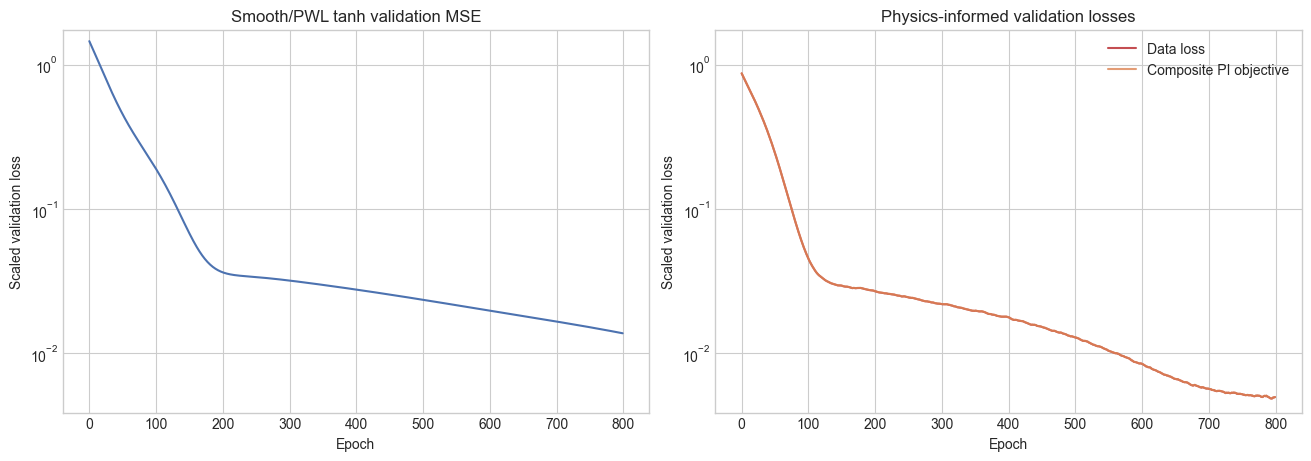

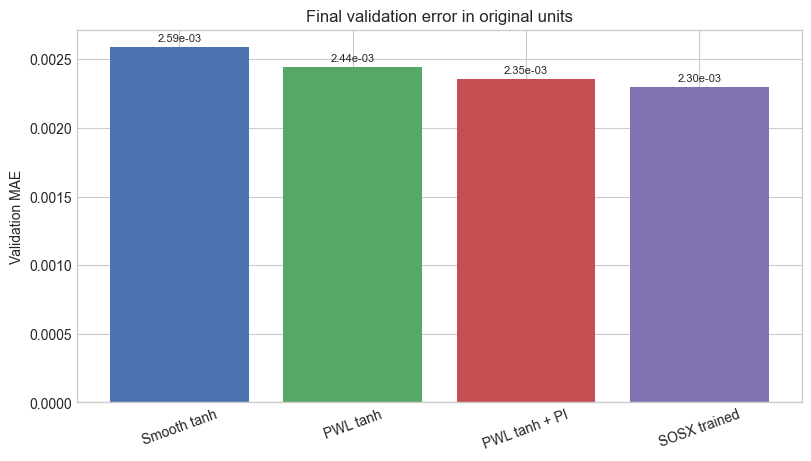

In [10]:
smooth_history = smooth.trainer.history_ or {}
pi_history = pi.trainer.history_ or {}

smooth_val = np.asarray(smooth_history.get("val_loss", []), dtype=float)
pi_val_data = np.asarray(pi_history.get("val_data_loss", []), dtype=float)
pi_val_total = np.asarray(pi_history.get("val_loss", []), dtype=float)
positive_histories = [
    values[values > 0]
    for values in (smooth_val, pi_val_data, pi_val_total)
    if values.size
]
history_ymin = min(values.min() for values in positive_histories) * 0.8
history_ymax = max(values.max() for values in positive_histories) * 1.2

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

axes[0].plot(smooth_val, color=method_colors["Smooth tanh"])
axes[0].set_title("Smooth/PWL tanh validation MSE")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Scaled validation loss")
axes[0].set_yscale("log")
axes[0].set_ylim(history_ymin, history_ymax)

axes[1].plot(pi_val_data, label="Data loss", color=method_colors["PWL tanh + PI"])
axes[1].plot(pi_val_total, label="Composite PI objective", color="#DD8452", alpha=0.8)
axes[1].set_title("Physics-informed validation losses")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Scaled validation loss")
axes[1].set_yscale("log")
axes[1].set_ylim(history_ymin, history_ymax)
axes[1].legend(frameon=False)

plt.show()

validation_mae = (
    metrics[metrics["split"] == "validation"]
    .set_index("method")
    .loc[list(predictors), "MAE"]
)
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
bars = ax.bar(
    validation_mae.index,
    validation_mae.values,
    color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"],
)
ax.set_ylabel("Validation MAE")
ax.set_title("Final validation error in original units")
ax.tick_params(axis="x", rotation=20)
ax.bar_label(bars, fmt="%.2e", padding=3, fontsize=8)

plt.show()

## 7 · CPU training benchmark

`PWL tanh` shares the smooth fit and adds only deterministic conversion at
inference/embedding time. `SOSX trained` includes the smooth warm-start fit plus
the SOSX refinement. The table also exposes incremental times to avoid hiding
that dependency.

,pipeline,fit stage [s],end-to-end training [s],notes
0,Smooth tanh,74.766473,74.766473,data-only Keras
1,PWL tanh,0.000000,74.766473,shares smooth weights; post-training PWL conve...
2,PWL tanh + PI,14.309173,14.309173,physics-informed Keras
3,SOSX trained,1.525982,76.292454,warm-start + SOSX; 2 LP nodes


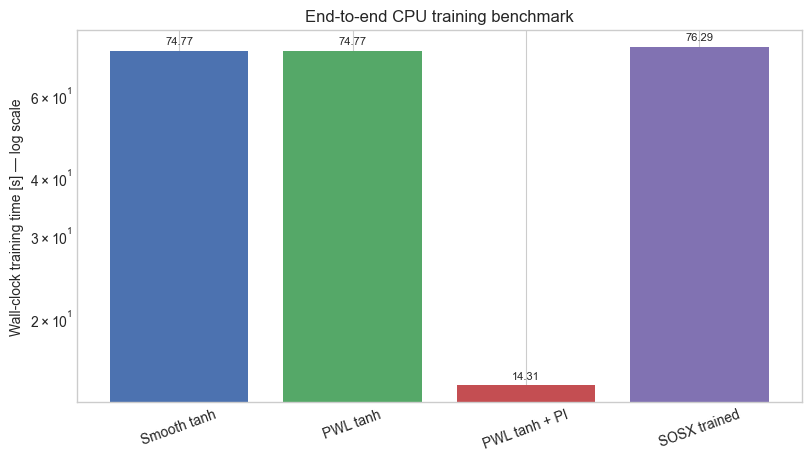

In [11]:
training_benchmark = pd.DataFrame(
    [
        {
            "pipeline": "Smooth tanh",
            "fit stage [s]": smooth_fit_seconds,
            "end-to-end training [s]": smooth_fit_seconds,
            "notes": "data-only Keras",
        },
        {
            "pipeline": "PWL tanh",
            "fit stage [s]": 0.0,
            "end-to-end training [s]": smooth_fit_seconds,
            "notes": "shares smooth weights; post-training PWL conversion",
        },
        {
            "pipeline": "PWL tanh + PI",
            "fit stage [s]": pi_fit_seconds,
            "end-to-end training [s]": pi_fit_seconds,
            "notes": "physics-informed Keras",
        },
        {
            "pipeline": "SOSX trained",
            "fit stage [s]": sosx_incremental_seconds,
            "end-to-end training [s]": sosx_total_seconds,
            "notes": f"warm-start + SOSX; {sosx.trainer.n_nodes_} LP nodes",
        },
    ]
)
display(training_benchmark)

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
bars = ax.bar(
    training_benchmark["pipeline"],
    training_benchmark["end-to-end training [s]"],
    color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"],
)
ax.set_yscale("log")
ax.set_ylabel("Wall-clock training time [s] — log scale")
ax.set_title("End-to-end CPU training benchmark")
ax.tick_params(axis="x", rotation=20)
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
plt.show()

## 8 · Constrained Williams–Otto solve benchmark

The operating constraints are `XA <= 0.12` and `XG <= 0.08`.

- Smooth tanh uses OMLT's exact smooth NLP and Ipopt.
- Data-only PWL and PI-PWL use the big-M MILP with HiGHS.
- The SOSX-trained network uses the binary-free SOSX branch-and-LP engine.

Every selected operating point is re-evaluated with the exact Williams–Otto
simulator. `true profit` and `true feasible` are therefore the downstream
quality measures. Missing Ipopt causes only the smooth row to be skipped.

In [12]:
def optimization_row(pipeline, formulation, result, wall_seconds):
    return {
        "pipeline": pipeline,
        "formulation": formulation,
        "solver": result.solver_name,
        "status": result.status,
        "FB": result.fb,
        "TR": result.tr,
        "surrogate profit": result.surrogate_profit,
        "true profit": result.exact_profit,
        "profit gap vs exact": EXACT_OPTIMUM["profit"] - result.exact_profit,
        "true feasible": result.exact_feasible,
        "solver time [s]": (
            result.solve_seconds
            if hasattr(result, "solve_seconds")
            else result.solver_seconds
        ),
        "end-to-end solve [s]": wall_seconds,
        "nodes": getattr(result, "n_nodes", np.nan),
    }


solve_rows = []
ipopt_path = find_ipopt()
if ipopt_path is not None:
    t0 = time.perf_counter()
    result = solve_surrogate_optimization_model(
        smooth.network,
        formulation="tanh_exact",
        solver="ipopt",
        executable=ipopt_path,
        params=params,
        include_operating_constraints=True,
        profit_formulation="bilinear",
    )
    solve_rows.append(
        optimization_row("Smooth tanh", "exact tanh NLP", result, time.perf_counter() - t0)
    )
else:
    solve_rows.append(
        {
            "pipeline": "Smooth tanh",
            "formulation": "exact tanh NLP",
            "solver": "ipopt",
            "status": "skipped: Ipopt unavailable",
        }
    )

for pipeline, network in [
    ("PWL tanh", smooth.network),
    ("PWL tanh + PI", pi.network),
]:
    t0 = time.perf_counter()
    result = solve_surrogate_optimization_model(
        network,
        formulation="tanh_pwl_bigm",
        solver=SOLVER,
        params=params,
        include_operating_constraints=True,
        profit_formulation="piecewise_mccormick",
        breakpoints=PWL_BREAKPOINTS,
        fb_segments=PWL_FB_SEGMENTS,
    )
    solve_rows.append(
        optimization_row(pipeline, "PWL tanh big-M MILP", result, time.perf_counter() - t0)
    )

t0 = time.perf_counter()
sosx_result = solve_sosx(
    sosx.network,
    solver=SOLVER,
    solver_options={"persistent": True},
    params=params,
    include_operating_constraints=True,
    profit_formulation="piecewise_mccormick",
    breakpoints=PWL_BREAKPOINTS,
    max_nodes=SOSX_MAX_NODES,
    time_limit=SOSX_TIME_LIMIT,
    relative_gap=SOSX_RELATIVE_GAP,
)
solve_rows.append(
    optimization_row(
        "SOSX trained",
        "SOSX branch-and-LP",
        sosx_result,
        time.perf_counter() - t0,
    )
)

solve_benchmark = pd.DataFrame(solve_rows)
display(solve_benchmark)

,pipeline,formulation,solver,status,FB,TR,surrogate profit,true profit,profit gap vs exact,true feasible,solver time [s],end-to-end solve [s],nodes
0,Smooth tanh,exact tanh NLP,ipopt,ok,4.424641,79.498426,64.743514,70.443145,5.376855,False,0.057603,0.399120,NaN
1,PWL tanh,PWL tanh big-M MILP,appsi_gurobi,ok,4.487856,79.802932,52.132868,69.718640,6.101360,True,0.065181,0.077533,NaN
2,PWL tanh + PI,PWL tanh big-M MILP,appsi_gurobi,ok,4.254168,79.711796,73.120714,76.383545,-0.563545,False,0.052860,0.065940,NaN
3,SOSX trained,SOSX branch-and-LP,appsi_gurobi,gap_limit,4.490534,80.605672,60.449207,73.218788,2.601212,True,0.420955,0.441445,29.0


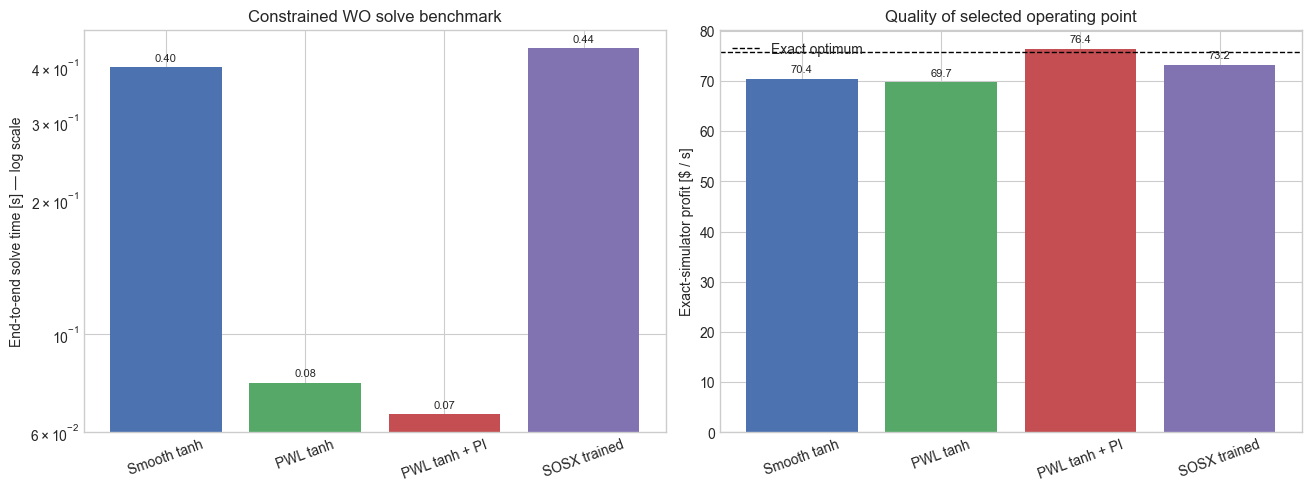

In [13]:
solved = solve_benchmark[solve_benchmark["end-to-end solve [s]"].notna()].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)

bars = axes[0].bar(
    solved["pipeline"],
    solved["end-to-end solve [s]"],
    color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"][: len(solved)],
)
axes[0].set_yscale("log")
axes[0].set_ylabel("End-to-end solve time [s] — log scale")
axes[0].set_title("Constrained WO solve benchmark")
axes[0].tick_params(axis="x", rotation=20)
axes[0].bar_label(bars, fmt="%.2f", padding=3, fontsize=8)

profit_bars = axes[1].bar(
    solved["pipeline"],
    solved["true profit"],
    color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"][: len(solved)],
)
axes[1].axhline(
    EXACT_OPTIMUM["profit"],
    color="black",
    linestyle="--",
    linewidth=1,
    label="Exact optimum",
)
axes[1].set_ylabel("Exact-simulator profit [$ / s]")
axes[1].set_title("Quality of selected operating point")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(frameon=False)
axes[1].bar_label(profit_bars, fmt="%.1f", padding=3, fontsize=8)

plt.show()

## 9 · Dense profit and constraint diagnostics

The tables above say whether each pipeline fits and optimizes well at sampled
points. This section adds the missing spatial diagnostics: exact process profit,
surrogate-implied profit, profit error, and learned feasibility boundaries over a
dense Williams-Otto operating grid. These plots explain *where* the embedded
optimizer may be optimistic, conservative, or wrong about the `XA`/`XG` limits.

In [14]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe


def grid_values(frame, column):
    pivot = frame.pivot(index="TR", columns="FB", values=column).sort_index()
    fb = pivot.columns.to_numpy(dtype=float)
    tr = pivot.index.to_numpy(dtype=float)
    return np.meshgrid(fb, tr), pivot.to_numpy(dtype=float)


def exact_feasible_from_frame(frame):
    return (
        (frame["XA"].to_numpy(dtype=float) <= params.xa_max)
        & (frame["XG"].to_numpy(dtype=float) <= params.xg_max)
    )


def predicted_profit_from_outputs(frame, suffix="_pred"):
    flow = params.fa + frame["FB"].to_numpy(dtype=float)
    xp = frame[f"XP{suffix}"].to_numpy(dtype=float)
    xe = frame[f"XE{suffix}"].to_numpy(dtype=float)
    fb = frame["FB"].to_numpy(dtype=float)
    return (params.price_p * xp + params.price_e * xe) * flow - params.cost_a * params.fa - params.cost_b * fb


landscape = generate_dataset(
    n_samples=DIAGNOSTIC_GRID_AXIS * DIAGNOSTIC_GRID_AXIS,
    method="grid",
    random_state=RANDOM_SEED,
    params=params,
    as_frame=True,
)
landscape_X = landscape[INPUT_NAMES].to_numpy(dtype=float)
print(f"diagnostic grid: {DIAGNOSTIC_GRID_AXIS} x {DIAGNOSTIC_GRID_AXIS} = {len(landscape)} points")


diagnostic grid: 60 x 60 = 3600 points


In [15]:
landscape_rows = []
landscape_by_method = {}

for method, predict in predictors.items():
    frame = landscape.copy()
    pred = predict(landscape_X)
    for j, output in enumerate(OUTPUT_NAMES):
        frame[f"{output}_pred"] = pred[:, j]
    frame["profit_pred"] = predicted_profit_from_outputs(frame)
    frame["profit_abs_error"] = np.abs(frame["profit_pred"] - frame["profit"])
    frame["predicted_feasible"] = (
        (frame["XA_pred"] <= params.xa_max) & (frame["XG_pred"] <= params.xg_max)
    )
    frame["exact_feasible"] = exact_feasible_from_frame(frame)
    landscape_by_method[method] = frame

    mismatch = frame["predicted_feasible"].to_numpy() != frame["exact_feasible"].to_numpy()
    optimistic = frame["predicted_feasible"].to_numpy() & ~frame["exact_feasible"].to_numpy()
    conservative = ~frame["predicted_feasible"].to_numpy() & frame["exact_feasible"].to_numpy()
    landscape_rows.append(
        {
            "method": method,
            "profit grid MAE": float(frame["profit_abs_error"].mean()),
            "profit grid RMSE": float(np.sqrt(np.mean(np.square(frame["profit_pred"] - frame["profit"])))),
            "profit grid max abs error": float(frame["profit_abs_error"].max()),
            "feasibility mismatch rate": float(np.mean(mismatch)),
            "optimistic infeasible rate": float(np.mean(optimistic)),
            "conservative feasible rate": float(np.mean(conservative)),
        }
    )

landscape_metrics = pd.DataFrame(landscape_rows).sort_values("profit grid MAE")
display(landscape_metrics)


,method,profit grid MAE,profit grid RMSE,profit grid max abs error,feasibility mismatch rate,optimistic infeasible rate,conservative feasible rate
2,PWL tanh + PI,8.105196,12.097021,87.456038,0.016111,0.005000,0.011111
0,Smooth tanh,9.182931,13.611736,83.433148,0.046389,0.006111,0.040278
3,SOSX trained,11.118219,16.601398,94.223536,0.038611,0.005000,0.033611
1,PWL tanh,11.681891,16.619792,90.294531,0.045556,0.006111,0.039444


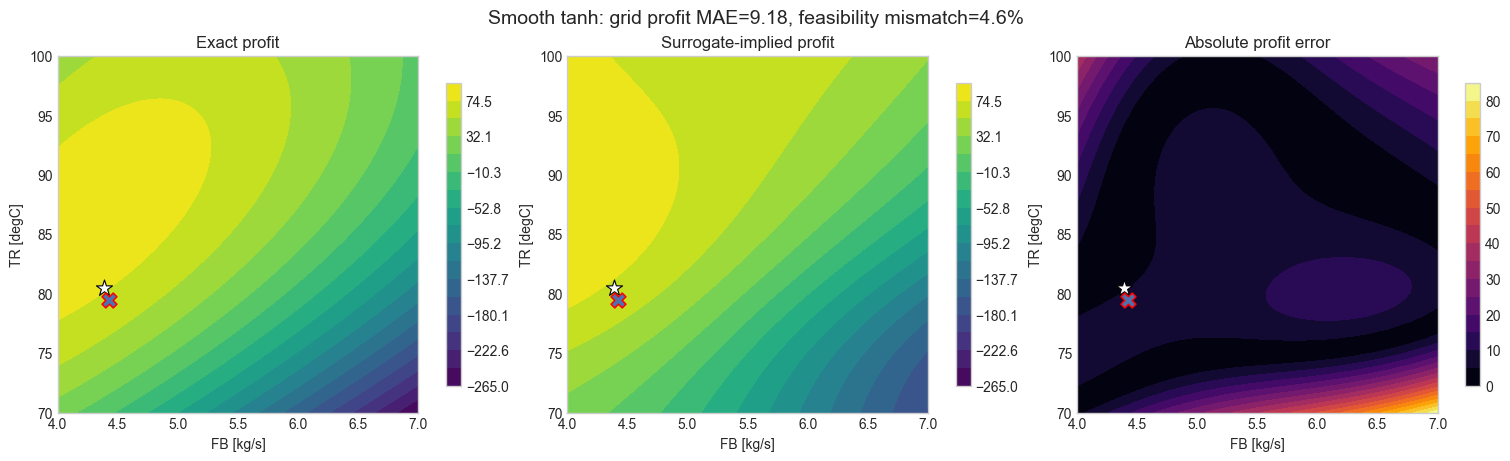

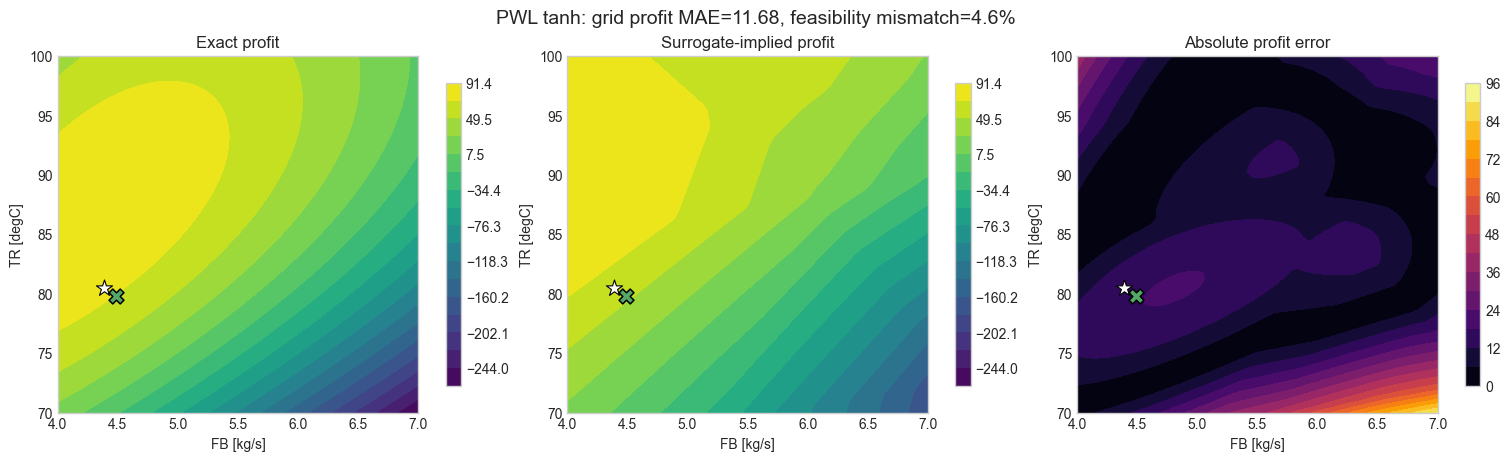

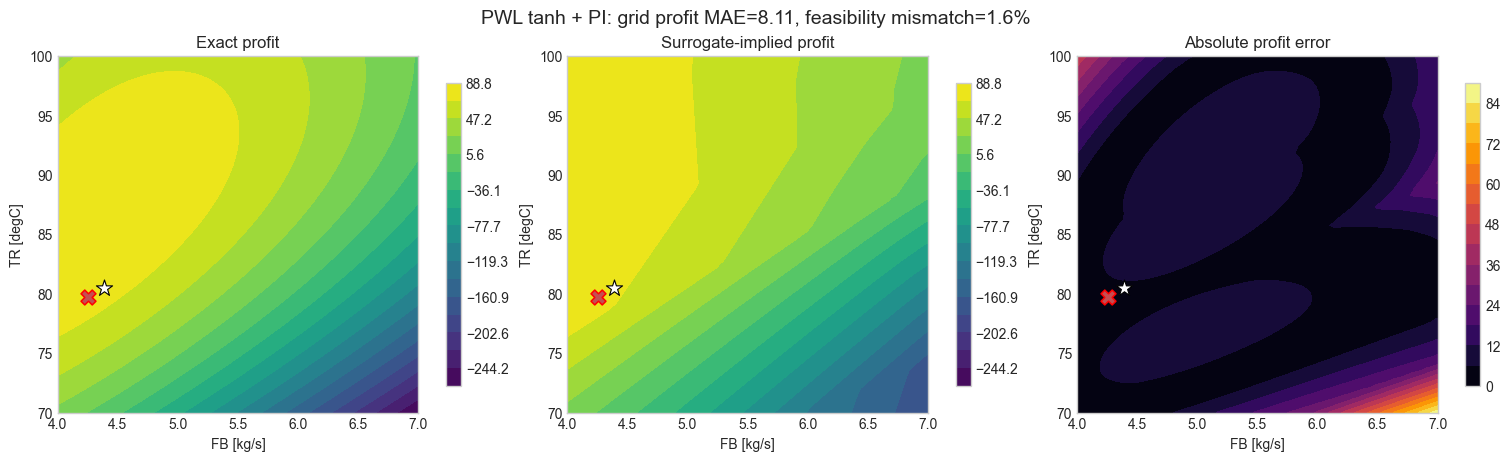

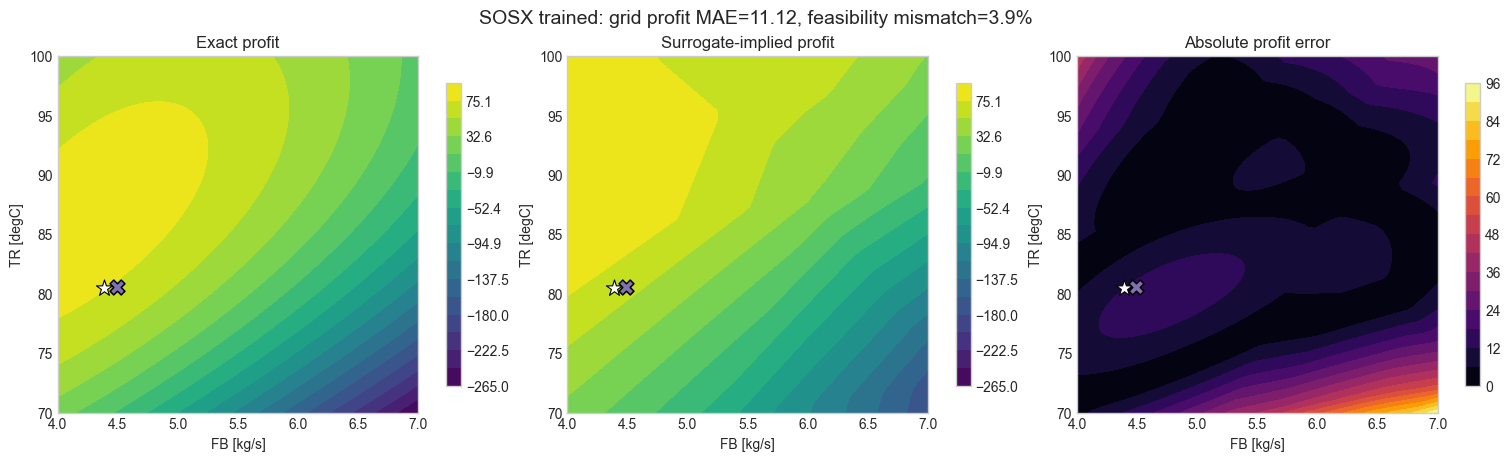

In [16]:
for method, frame in landscape_by_method.items():
    exact_profit = frame["profit"].to_numpy(dtype=float)
    surrogate_profit = frame["profit_pred"].to_numpy(dtype=float)
    profit_lo = float(min(exact_profit.min(), surrogate_profit.min()))
    profit_hi = float(max(exact_profit.max(), surrogate_profit.max()))
    profit_levels = np.linspace(profit_lo, profit_hi, 18)

    selected = solve_benchmark.loc[solve_benchmark["pipeline"] == method]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

    for ax, column, title, cmap in zip(
        axes,
        ["profit", "profit_pred", "profit_abs_error"],
        ["Exact profit", "Surrogate-implied profit", "Absolute profit error"],
        ["viridis", "viridis", "inferno"],
    ):
        (fb_grid, tr_grid), values = grid_values(frame, column)
        levels = profit_levels if column != "profit_abs_error" else 16
        contour = ax.contourf(fb_grid, tr_grid, values, levels=levels, cmap=cmap)
        ax.scatter(
            [EXACT_OPTIMUM["FB"]], [EXACT_OPTIMUM["TR"]],
            marker="*", s=150, color="white", edgecolor="black", linewidth=0.8, zorder=6,
        )
        if not selected.empty and pd.notna(selected.iloc[0].get("FB", np.nan)):
            row = selected.iloc[0]
            ax.scatter(
                [row["FB"]], [row["TR"]], marker="X", s=115,
                color=method_colors[method], edgecolor="black" if bool(row["true feasible"]) else "red",
                linewidth=1.1, zorder=7,
            )
        ax.set_title(title)
        ax.set_xlabel("FB [kg/s]")
        ax.set_ylabel("TR [degC]")
        fig.colorbar(contour, ax=ax, shrink=0.85)

    row = landscape_metrics.loc[landscape_metrics["method"] == method].iloc[0]
    fig.suptitle(
        f"{method}: grid profit MAE={row['profit grid MAE']:.2f}, "
        f"feasibility mismatch={100 * row['feasibility mismatch rate']:.1f}%",
        fontsize=14,
    )
    plt.show()


## 10 · Learned versus exact operating constraints

The embedded optimizer enforces `XA <= 0.12` and `XG <= 0.08` on the surrogate
outputs, not on the true Williams-Otto simulator. The exact constraint contours
therefore need to be compared with the learned contours for every pipeline.

saved C:\Users\Sunoy\University\PY_M_projects\PWLNet\images\article\wo_learned_constraints.pdf (+ .png)


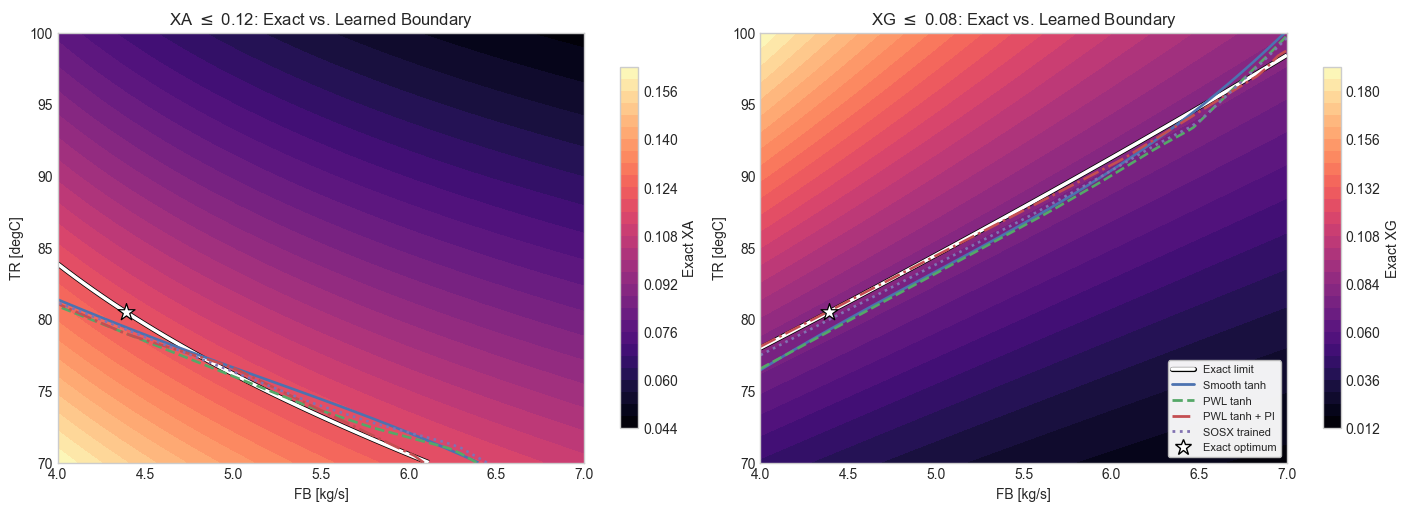

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
constraint_specs = [("XA", params.xa_max), ("XG", params.xg_max)]
linestyles = {
    "Smooth tanh": "solid",
    "PWL tanh": "dashed",
    "PWL tanh + PI": "dashdot",
    "SOSX trained": "dotted",
}

for ax, (name, limit) in zip(axes, constraint_specs):
    (fb_grid, tr_grid), exact = grid_values(landscape, name)
    contour = ax.contourf(fb_grid, tr_grid, exact, levels=30, cmap="magma")
    fig.colorbar(contour, ax=ax, shrink=0.84, label=f"Exact {name}")
    exact_line = ax.contour(fb_grid, tr_grid, exact, levels=[limit], colors="white", linewidths=2.6)
    exact_line.set_path_effects([pe.Stroke(linewidth=3.7, foreground="black"), pe.Normal()])

    for method, frame in landscape_by_method.items():
        _, learned = grid_values(frame, f"{name}_pred")
        ax.contour(
            fb_grid, tr_grid, learned, levels=[limit], colors=method_colors[method],
            linewidths=1.9, linestyles=linestyles[method],
        )

    ax.scatter(
        [EXACT_OPTIMUM["FB"]], [EXACT_OPTIMUM["TR"]], marker="*", s=165,
        color="white", edgecolor="black", linewidth=0.9, zorder=7,
    )
    ax.set_title(f"{name} $\\leq$ {limit:g}: Exact vs. Learned Boundary")
    ax.set_xlabel("FB [kg/s]")
    ax.set_ylabel("TR [degC]")

handles = [
    Line2D([0], [0], color="white", lw=2.6,
           path_effects=[pe.Stroke(linewidth=3.7, foreground="black"), pe.Normal()],
           label="Exact limit"),
]
handles.extend(
    Line2D([0], [0], color=method_colors[m], lw=2.0, linestyle=linestyles[m], label=m)
    for m in predictors
)
handles.append(
    Line2D([0], [0], marker="*", color="white", markeredgecolor="black", markersize=12,
           linestyle="None", label="Exact optimum")
)
axes[1].legend(handles=handles, loc="lower right", fontsize=8, frameon=True,
               framealpha=0.95, facecolor="white", edgecolor="#bbbbbb")
# High-quality manuscript export (vector PDF + 300-dpi PNG) -- article figure "wo_learned_constraints".
FIG_DIR = ROOT / "images" / "article"
FIG_DIR.mkdir(parents=True, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(FIG_DIR / f"wo_learned_constraints.{ext}", bbox_inches="tight", dpi=300)
print(f"saved {FIG_DIR / 'wo_learned_constraints.pdf'} (+ .png)")
plt.show()


## 11 · Constrained versus unconstrained operation

This section solves each native deployment path twice: once with the Williams-Otto
operating constraints and once as pure surrogate profit maximization. The exact
simulator is still used for final profit and feasibility, so any unsafe
unconstrained point is visible.

In [18]:
def solve_native_pipeline(method, constrained):
    include = bool(constrained)
    if method == "Smooth tanh":
        if ipopt_path is None:
            return None
        return solve_surrogate_optimization_model(
            smooth.network,
            formulation="tanh_exact",
            solver="ipopt",
            executable=ipopt_path,
            params=params,
            include_operating_constraints=include,
            profit_formulation="bilinear",
        )
    if method == "PWL tanh":
        return solve_surrogate_optimization_model(
            smooth.network,
            formulation="tanh_pwl_bigm",
            solver=SOLVER,
            params=params,
            include_operating_constraints=include,
            profit_formulation="piecewise_mccormick",
            breakpoints=PWL_BREAKPOINTS,
            fb_segments=PWL_FB_SEGMENTS,
        )
    if method == "PWL tanh + PI":
        return solve_surrogate_optimization_model(
            pi.network,
            formulation="tanh_pwl_bigm",
            solver=SOLVER,
            params=params,
            include_operating_constraints=include,
            profit_formulation="piecewise_mccormick",
            breakpoints=PWL_BREAKPOINTS,
            fb_segments=PWL_FB_SEGMENTS,
        )
    if method == "SOSX trained":
        return solve_sosx(
            sosx.network,
            solver=SOLVER,
            solver_options={"persistent": True},
            params=params,
            include_operating_constraints=include,
            profit_formulation="piecewise_mccormick",
            breakpoints=PWL_BREAKPOINTS,
            max_nodes=SOSX_MAX_NODES,
            time_limit=SOSX_TIME_LIMIT,
            relative_gap=SOSX_RELATIVE_GAP,
        )
    raise KeyError(method)


def result_row(method, case, result, wall_seconds):
    if result is None:
        return {
            "method": method,
            "case": case,
            "status": "skipped: solver unavailable",
        }
    return {
        "method": method,
        "case": case,
        "status": result.status,
        "FB": result.fb,
        "TR": result.tr,
        "surrogate profit": result.surrogate_profit,
        "true profit": result.exact_profit,
        "profit gap vs exact": EXACT_OPTIMUM["profit"] - result.exact_profit,
        "predicted XA": result.predicted_outputs["XA"],
        "predicted XG": result.predicted_outputs["XG"],
        "true XA": result.exact_outputs["XA"],
        "true XG": result.exact_outputs["XG"],
        "true feasible": result.exact_feasible,
        "solver time [s]": getattr(result, "solve_seconds", getattr(result, "solver_seconds", np.nan)),
        "end-to-end solve [s]": wall_seconds,
        "nodes": getattr(result, "n_nodes", np.nan),
    }

constraint_rows = []
constraint_results = {}
for method in predictors:
    for case, constrained in [("unconstrained", False), ("constrained", True)]:
        t0 = time.perf_counter()
        result = solve_native_pipeline(method, constrained)
        wall = time.perf_counter() - t0
        constraint_results[(method, case)] = result
        constraint_rows.append(result_row(method, case, result, wall))

constraint_benchmark = pd.DataFrame(constraint_rows)
display(constraint_benchmark)


,method,case,status,FB,TR,surrogate profit,true profit,profit gap vs exact,predicted XA,predicted XG,true XA,true XG,true feasible,solver time [s],end-to-end solve [s],nodes
0,Smooth tanh,unconstrained,ok,4.000000,87.370418,95.768094,86.235499,-10.415499,0.105342,0.123026,0.110084,0.126206,False,0.040116,0.045539,NaN
1,Smooth tanh,constrained,ok,4.424641,79.498426,64.743514,70.443145,5.376855,0.119244,0.080000,0.122105,0.074823,False,0.043138,0.048739,NaN
2,PWL tanh,unconstrained,ok,4.214183,85.299646,88.711611,88.573086,-12.753086,0.104878,0.106295,0.110418,0.107528,False,0.061814,0.073052,NaN
3,PWL tanh,constrained,ok,4.487856,79.802932,52.132868,69.718640,6.101360,0.116473,0.080000,0.119792,0.074443,True,0.063599,0.078192,NaN
4,PWL tanh + PI,unconstrained,ok,4.000000,84.870023,88.866573,88.159447,-12.339447,0.111283,0.106023,0.117107,0.113388,False,0.046992,0.058381,NaN
5,PWL tanh + PI,constrained,ok,4.254168,79.711796,73.120714,76.383545,-0.563545,0.120000,0.080000,0.125549,0.080385,False,0.052742,0.067310,NaN
6,SOSX trained,unconstrained,gap_limit,4.214289,85.281962,93.883648,88.565892,-12.745892,0.104911,0.104731,0.110465,0.107439,False,0.264823,0.282160,17.0
7,SOSX trained,constrained,gap_limit,4.490534,80.605672,60.449207,73.218788,2.601212,0.114749,0.080000,0.117409,0.077711,True,0.416219,0.439655,29.0


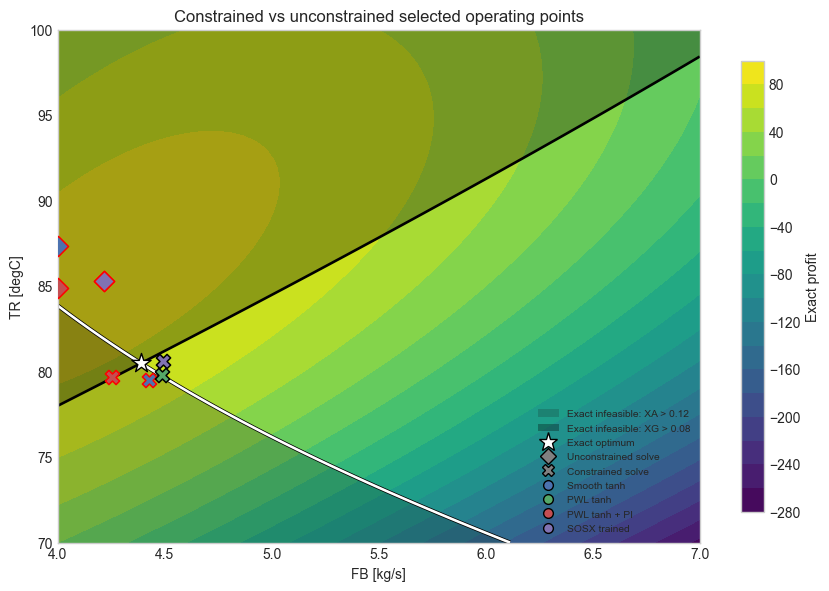

In [19]:
fig, ax = plt.subplots(figsize=(8.2, 5.8), constrained_layout=True)
base_frame = landscape_by_method["PWL tanh"]
(fb_grid, tr_grid), profit_grid = grid_values(landscape, "profit")
_, xa_grid = grid_values(landscape, "XA")
_, xg_grid = grid_values(landscape, "XG")
contour = ax.contourf(fb_grid, tr_grid, profit_grid, levels=18, cmap="viridis")

xa_upper = float(np.nanmax(xa_grid))
xg_upper = float(np.nanmax(xg_grid))
if xa_upper > params.xa_max:
    ax.contourf(fb_grid, tr_grid, xa_grid, levels=[params.xa_max, xa_upper], colors=["#171717"], alpha=0.20)
if xg_upper > params.xg_max:
    ax.contourf(fb_grid, tr_grid, xg_grid, levels=[params.xg_max, xg_upper], colors=["#000000"], alpha=0.30)

xa_line = ax.contour(fb_grid, tr_grid, xa_grid, levels=[params.xa_max], colors="white", linewidths=1.9)
xa_line.set_path_effects([pe.Stroke(linewidth=3.0, foreground="black"), pe.Normal()])
ax.contour(fb_grid, tr_grid, xg_grid, levels=[params.xg_max], colors="black", linewidths=1.9)
ax.scatter([EXACT_OPTIMUM["FB"]], [EXACT_OPTIMUM["TR"]], marker="*", s=210, color="white", edgecolor="black", linewidth=1.0, zorder=8)

for method in predictors:
    for case, marker in [("unconstrained", "D"), ("constrained", "X")]:
        result = constraint_results.get((method, case))
        if result is None:
            continue
        ax.scatter(
            [result.fb], [result.tr], marker=marker, s=105,
            color=method_colors[method], edgecolor="black" if result.exact_feasible else "red",
            linewidth=1.1, zorder=7,
        )

ax.set_title("Constrained vs unconstrained selected operating points")
ax.set_xlabel("FB [kg/s]")
ax.set_ylabel("TR [degC]")
fig.colorbar(contour, ax=ax, shrink=0.88, label="Exact profit")
legend_handles = [
    Patch(facecolor="#171717", alpha=0.20, label="Exact infeasible: XA > 0.12"),
    Patch(facecolor="#000000", alpha=0.30, label="Exact infeasible: XG > 0.08"),
    Line2D([0], [0], marker="*", color="white", markeredgecolor="black", markersize=14, linestyle="None", label="Exact optimum"),
    Line2D([0], [0], marker="D", color="gray", markeredgecolor="black", markersize=8, linestyle="None", label="Unconstrained solve"),
    Line2D([0], [0], marker="X", color="gray", markeredgecolor="black", markersize=9, linestyle="None", label="Constrained solve"),
]
legend_handles.extend(
    Line2D([0], [0], marker="o", color=method_colors[m], markeredgecolor="black", markersize=7, linestyle="None", label=m)
    for m in predictors
)
ax.legend(handles=legend_handles, loc="lower right", fontsize=7.4, framealpha=0.95)
plt.show()


## 12 · Breakpoint and economics sensitivity

This separates two approximation layers that the native benchmark otherwise mixes:
activation discretization and economic relaxation. The prediction sweep changes
only the PWL tanh breakpoint count. The solve table changes the profit formulation
for the same PWL network and solver.

method,PWL tanh,PWL tanh + PI,SOSX trained
breakpoints,,,
3,0.004096,0.003439,0.003611
5,0.003336,0.002859,0.003110
7,0.003164,0.002754,0.003079


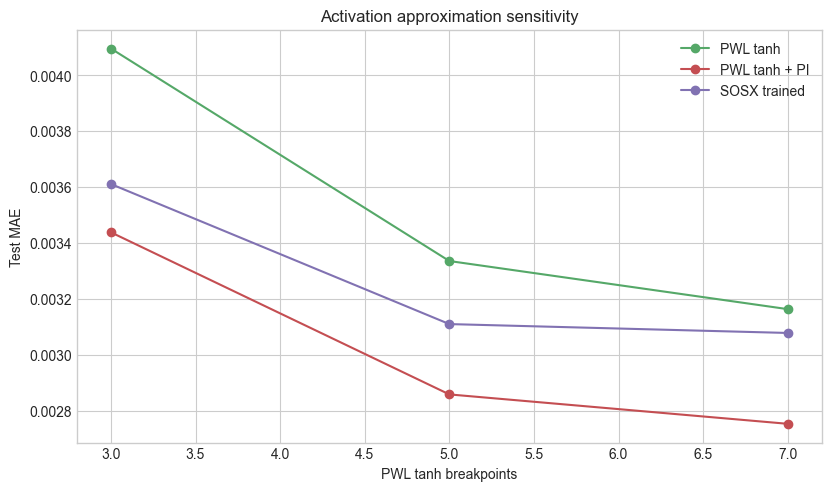

In [20]:
breakpoint_rows = []
for bp in BREAKPOINT_SWEEP:
    for label, network in [("PWL tanh", smooth.network), ("PWL tanh + PI", pi.network), ("SOSX trained", sosx.network)]:
        y_pred = evaluate_tanh_pwl_network(network, X_test, breakpoints=bp)
        row = {"method": label, "breakpoints": bp, **regression_metrics(y_test, y_pred)}
        breakpoint_rows.append(row)

breakpoint_metrics = pd.DataFrame(breakpoint_rows)
display(breakpoint_metrics.pivot(index="breakpoints", columns="method", values="MAE"))

fig, ax = plt.subplots(figsize=(8.2, 4.8), constrained_layout=True)
for method, group in breakpoint_metrics.groupby("method"):
    ax.plot(group["breakpoints"], group["MAE"], marker="o", label=method, color=method_colors[method])
ax.set_xlabel("PWL tanh breakpoints")
ax.set_ylabel("Test MAE")
ax.set_title("Activation approximation sensitivity")
ax.legend(frameon=False)
plt.show()


In [21]:
economics_rows = []
for profit_formulation, fb_segments in [("mccormick", 1), ("piecewise_mccormick", PWL_FB_SEGMENTS)]:
    t0 = time.perf_counter()
    result = solve_surrogate_optimization_model(
        smooth.network,
        formulation="tanh_pwl_bigm",
        solver=SOLVER,
        params=params,
        include_operating_constraints=True,
        profit_formulation=profit_formulation,
        breakpoints=PWL_BREAKPOINTS,
        fb_segments=fb_segments,
    )
    economics_rows.append(
        {
            "network": "PWL tanh",
            "profit formulation": profit_formulation,
            "FB segments": fb_segments,
            "FB": result.fb,
            "TR": result.tr,
            "surrogate profit": result.surrogate_profit,
            "relaxed objective": result.objective_value,
            "true profit": result.exact_profit,
            "profit gap vs exact": EXACT_OPTIMUM["profit"] - result.exact_profit,
            "true feasible": result.exact_feasible,
            "solve [s]": time.perf_counter() - t0,
        }
    )

economics_benchmark = pd.DataFrame(economics_rows)
display(economics_benchmark)


,network,profit formulation,FB segments,FB,TR,surrogate profit,relaxed objective,true profit,profit gap vs exact,true feasible,solve [s]
0,PWL tanh,mccormick,1,5.662844,87.615003,43.290783,85.250469,51.882858,23.937142,True,0.045597
1,PWL tanh,piecewise_mccormick,10,4.487856,79.802932,52.132868,56.691292,69.718640,6.101360,True,0.078250


## 13 · Common-formulation network comparison

The native benchmark is intentionally end-to-end: smooth tanh uses an NLP, PWL
models use big-M MILPs, and SOSX uses branch-and-LP. This table holds the solver
formulation fixed by embedding every tanh-family network as the same PWL big-M
MILP. It is the controlled comparison for network weights and learned outputs.

## common_formulation_rows = []
for method, network in [
    ("PWL tanh", smooth.network),
    ("PWL tanh + PI", pi.network),
    ("SOSX trained", sosx.network),
]:
    t0 = time.perf_counter()
    result = solve_surrogate_optimization_model(
        network,
        formulation="tanh_pwl_bigm",
        solver=SOLVER,
        params=params,
        include_operating_constraints=True,
        profit_formulation="piecewise_mccormick",
        breakpoints=PWL_BREAKPOINTS,
        fb_segments=PWL_FB_SEGMENTS,
    )
    common_formulation_rows.append(result_row(method, "common PWL big-M", result, time.perf_counter() - t0))

common_formulation_benchmark = pd.DataFrame(common_formulation_rows)
display(common_formulation_benchmark)


## 14 · Optional robustness, pruning, and repeated-seed evidence

The following cell is disabled by default because it can multiply runtime. Enable
`RUN_EXTENDED_SOSX_DIAGNOSTICS` in the configuration cell when preparing release
evidence. It adds the remaining heavy checks: input-noise sweeps, a small pruning
variant, and repeated train/split seeds.

In [22]:
if RUN_EXTENDED_SOSX_DIAGNOSTICS:
    rng = np.random.default_rng(RANDOM_SEED + 1000)
    input_lower = np.array([params.fb_bounds[0], params.tr_bounds[0]], dtype=float)
    input_upper = np.array([params.fb_bounds[1], params.tr_bounds[1]], dtype=float)
    input_range = input_upper - input_lower

    noise_rows = []
    for frac in NOISE_STRESS_FRACTIONS:
        for repeat in range(REPEATED_SEED_COUNT):
            noise = rng.normal(0.0, frac * input_range, size=X_test.shape)
            X_noisy = np.clip(X_test + noise, input_lower, input_upper)
            for method, predict in predictors.items():
                y_pred = predict(X_noisy)
                noise_rows.append(
                    {"noise fraction": frac, "repeat": repeat, "method": method, **regression_metrics(y_test, y_pred)}
                )
    noise_stress_summary = (
        pd.DataFrame(noise_rows)
        .groupby(["noise fraction", "method"])[["MAE", "RMSE", "R2"]]
        .agg(["mean", "std"])
    )
    display(noise_stress_summary)

    pruned = PWLNet(smooth.network).prune("neuron", fraction=0.25, X=X_train)
    pin_operating_bounds(pruned)
    y_pruned = evaluate_tanh_pwl_network(pruned.network, X_test, breakpoints=PWL_BREAKPOINTS)
    pruned_metrics = pd.DataFrame([
        {"model": "PWL tanh", "hidden": HIDDEN, **regression_metrics(y_test, predictions["PWL tanh"]["test"])},
        {"model": "PWL tanh pruned", "hidden": pruned.summary().n_neurons, **regression_metrics(y_test, y_pruned)},
    ])
    display(pruned_metrics)

    repeated_rows = []
    for seed in range(RANDOM_SEED, RANDOM_SEED + REPEATED_SEED_COUNT):
        split_i = train_val_test_split(data, val_size=0.2, test_size=0.2, random_state=seed)
        Xi_train, yi_train = split_xy(split_i.train)
        Xi_val, yi_val = split_xy(split_i.validation)
        Xi_test, yi_test = split_xy(split_i.test)
        model_i = PWLNet.train(
            Xi_train, yi_train,
            hidden_layers=[HIDDEN], activation="tanh", loss="mse",
            epochs=max(100, EPOCHS // 4), batch_size=BATCH_SIZE,
            validation_data=(Xi_val, yi_val), early_stopping_patience=25,
            random_seed=seed, verbose=0,
        )
        pin_operating_bounds(model_i)
        y_i = evaluate_tanh_pwl_network(model_i.network, Xi_test, breakpoints=PWL_BREAKPOINTS)
        repeated_rows.append({"seed": seed, **regression_metrics(yi_test, y_i)})
    repeated_seed_summary = pd.DataFrame(repeated_rows)
    display(repeated_seed_summary)
else:
    print("Extended SOSX diagnostics are disabled. Set RUN_EXTENDED_SOSX_DIAGNOSTICS = True to run them.")


Extended SOSX diagnostics are disabled. Set RUN_EXTENDED_SOSX_DIAGNOSTICS = True to run them.


## 15 · Summary

Read the results along three separate axes:

1. **Prediction quality:** test MAE/RMSE/R² and parity.
2. **Training cost:** gradient fit versus physics-informed fit versus global
   SOSX refinement.
3. **Decision quality and solve cost:** exact-simulator profit and feasibility
   at the optimizer-selected point, alongside native formulation time.
4. **Spatial diagnostics and sensitivity:** profit landscapes, learned constraint
   boundaries, breakpoint/economics sensitivity, and common-formulation solves.

Important interpretation points:

- Smooth and PWL tanh differ only by activation approximation, not weights.
- PI may sacrifice a small amount of data fit to improve closure/bound behavior.
- SOSX optimizes PWL-MAE with fixed output weights; it is not solving the same
  unconstrained training problem as Keras MSE.
- The native solve benchmark intentionally includes formulation differences.
  Use a common big-M formulation for all networks if the goal is to isolate only
  network weights.
- Wall-clock timings are meaningful only on the same machine, with the same
  solver versions, thread settings, and a warm Python environment.